# The integral of the six channels, mapped onto the face of the detector

*First notebook of `relcal` (relative calibration between channels). Draft prepared with Claude Code for A. Villano, 2026-10-30.*

This notebook reads the quantities that `goldsluice` computed from the 12 Side-2 series of Run 76 (`data_analysis/R76/processing/r76-d-idx.dataset.toml`, output in `C:/NSDF/goldsluice-output/r76-d-idx`), takes the `integral` of each of the six channels, and shows where on the face of the detector the events are, with a drawing of the detector under every plot. It never touches the raw data.

**What `integral` is.** The sum of the baseline-subtracted trace times the sample period, in ADC counts times seconds. No channel is calibrated to energy or current yet; comparing the channels with each other is the point of this folder (see `README.md`).

**Where an event is.** There is no position reconstruction. The place of an event on the face is the *integral-weighted centre* of the six regions: the centroid of each region weighted by the integral of its channel (the same rough guide as in `../pulse-normalization/detector_layout.py`). The ring channels `A`, `B` and the centre disc `F` all have their centroid at the centre of the face, so an event seen mostly by them lands at the centre; only `C`, `D`, `E` pull it sideways. The position is made from the very integrals that are plotted, so a map of the integral against that position is partly circular: it shows how the channels share the signal, which is what a relative calibration needs, not an independent check.

Needs `goldpan` (installed by `requirements.txt`). Run with the `darkmatter_cli_env` kernel. The first read of the whole data set takes a couple of minutes (8 million events); the integrals are then kept in `~/goldsluice-output/relcal-integral.npz`, outside the repository, so the next run takes seconds.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm, colors
from matplotlib.patches import Wedge

from goldpan.dataset import Dataset

In [2]:
# Find the definition file by walking up to the repository's data_analysis/R76/processing folder.
_here = Path.cwd().resolve()
DEFINITION = next(p / "data_analysis" / "R76" / "processing" / "r76-d-idx.dataset.toml"
                  for p in [_here, *_here.parents] if (p / "data_analysis" / "R76" / "processing").is_dir())
CACHE = Path.home() / "goldsluice-output" / "relcal-integral.npz"
LETTERS = "ABCDEF"

if CACHE.exists():
    z = np.load(CACHE)
    integral = {k: z[k] for k in LETTERS}
    series, dump, event = z["series"], z["dump"], z["event"]
else:
    ds = Dataset.open(DEFINITION)
    q = ds.processed()                               # the quantities only, no pulses
    integral = {k: np.asarray(q.quantities[f"Side2p{k}"]["integral"], dtype=float) for k in LETTERS}
    series, dump, event = np.asarray(q.quantities["series"]).astype(str), np.asarray(q.quantities["dump"]), np.asarray(q.quantities["event"])
    CACHE.parent.mkdir(exist_ok=True)
    np.savez(CACHE, **integral, series=series, dump=dump, event=event)
    del q

I = np.column_stack([integral[k] for k in LETTERS])   # (events, 6): columns A to F
print(f"{len(I):,} events from {len(np.unique(series))} series; {np.isnan(I).any(axis=1).sum():,} with a missing integral")
print(f"{'':10}" + "".join(f"{k:>10}" for k in LETTERS))
print(f"{'median':10}" + "".join(f"{v:>10.3f}" for v in np.nanmedian(I, axis=0)))
print(f"{'99th pct':10}" + "".join(f"{v:>10.3f}" for v in np.nanpercentile(I, 99, axis=0)))

8,005,389 events from 12 series; 0 with a missing integral
                   A         B         C         D         E         F


median         0.130     0.138     0.118     0.120     0.108     0.162


99th pct       2.362     2.039     0.943     1.763     1.115     1.548


## The trigger type of every event

The processed quantities do not carry the trigger type (the label that the dump's `.csv` gives each event); it is read here from the `.csv` files of the raw dumps in `C:/NSDF/idx` and joined to the integrals by series, dump and event number. Reading 3,000 small files takes a minute or two the first time; the labels are kept in `~/goldsluice-output/relcal-trigger.npz`. (When `goldsluice` writes the trigger type with the quantities, this cell goes.)

In [3]:
import csv

TRIG_CACHE = Path.home() / "goldsluice-output" / "relcal-trigger.npz"
RAW = Path("C:/NSDF/idx")

if not TRIG_CACHE.exists():
    S_, D_, E_, T_ = [], [], [], []
    for f in sorted(RAW.glob("0722*_F[0-9][0-9][0-9][0-9]/*.csv")):
        s, d = f.stem.rsplit("_", 1)                  # series, dump ("F0001")
        with open(f, newline="") as fh:
            rows = csv.reader(fh)
            next(rows)                                # event, trigger_type, readout_type, global_timestamp
            for row in rows:
                S_.append(s); D_.append(int(d[1:])); E_.append(int(row[0])); T_.append(row[1])
    np.savez(TRIG_CACHE, series=S_, dump=D_, event=E_, trigger_type=T_)
t = np.load(TRIG_CACHE)

def event_key(s, d, e):
    """One integer per (series, dump, event), to join the two tables."""
    ser = np.unique(series)
    names, inverse = np.unique(np.asarray(d).astype(str), return_inverse=True)
    dn = np.array([int(x.lstrip("F")) for x in names])[inverse]          # "F0001" or 1 -> 1
    return (np.searchsorted(ser, s).astype(np.int64) * 10_000 + dn) * 100_000_000 + np.asarray(e, dtype=np.int64)

kt = event_key(t["series"], t["dump"], t["event"])
order = np.argsort(kt)
where = np.searchsorted(kt[order], event_key(series, dump, event))
trigger = t["trigger_type"][order][np.minimum(where, len(kt) - 1)]
assert (kt[order][np.minimum(where, len(kt) - 1)] == event_key(series, dump, event)).all(), "events without a trigger label"
print({str(k): int((trigger == k).sum()) for k in np.unique(trigger)}, "(events in the .csv files but not in the processed data: " f"{len(kt) - len(trigger):,}" ")")

{'Physics': 713829, 'Unknown': 7291560} (events in the .csv files but not in the processed data: 1,009,377)


## Which events

Two cuts. **Real triggers**: the events whose trigger type is not `Physics`. The names of the labels are the other way round in these dumps: the events labelled `Physics` are the random triggers (below: almost none of them has a pulse), and the real, pulse-triggered events are labelled `Unknown`. This is the working assumption of `goldpan.cuts.real_triggers` and `randoms`, from Note 2a, not confirmed against the DAQ configuration; the table shows what the data say. **Pulse size**: the sum of the positive integrals of the six channels, `total`, above `THRESH`; a per-channel offset is taken off first (the median integral of the channel, about 0.1 ADC counts x s: the integral of a trace with no pulse is not exactly zero). The threshold is a choice, change it and rerun.

  trigger type      events  median total  share with total > 2.0


       Physics     713,829         0.000                    2.4%


       Unknown   7,291,560         0.238                   28.6%



real triggers with total > 2.0: 2,083,482 of 8,005,389 events (26.0%)


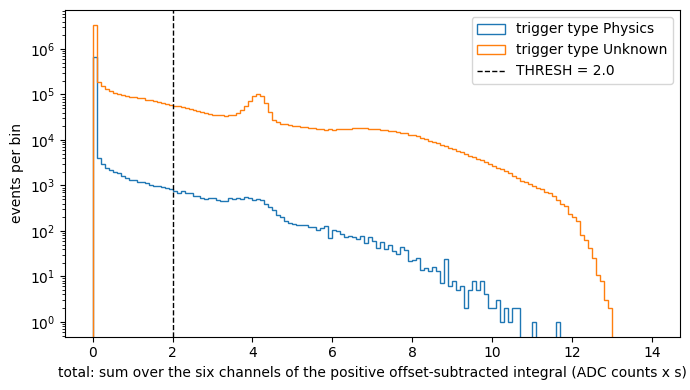

In [4]:
offset = np.nanmedian(I, axis=0)
S = I - offset                                        # offset-subtracted integrals
total = np.nansum(np.clip(S, 0, None), axis=1)

THRESH = 2.0                                          # ADC counts x s: a choice, not a derived number
REAL = "Unknown"                                      # the label of the real (pulse-triggered) events, see above

print(f"{'trigger type':>14}{'events':>12}{'median total':>14}{'share with total > ' + str(THRESH):>24}")
for label in np.unique(trigger):
    m = trigger == label
    print(f"{label:>14}{m.sum():>12,}{np.median(total[m]):>14.3f}{(total[m] > THRESH).mean():>24.1%}")

real = trigger == REAL
use = real & np.isfinite(total) & (total > THRESH)
print()
print(f"real triggers with total > {THRESH}: {use.sum():,} of {len(total):,} events ({use.mean():.1%})")

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, 14, 141)
for label in np.unique(trigger):
    ax.hist(np.clip(total[trigger == label], 0, bins[-1]), bins=bins, histtype="step", label=f"trigger type {label}")
ax.axvline(THRESH, color="k", ls="--", lw=1, label=f"THRESH = {THRESH}")
ax.set_yscale("log")
ax.set_xlabel("total: sum over the six channels of the positive offset-subtracted integral (ADC counts x s)")
ax.set_ylabel("events per bin")
ax.legend()
fig.tight_layout()
plt.show()

## The detector, and the place of an event on it

The face is drawn as in the Note 9 channel figure and the wiki, seen after flipping the detector over: `A` the outer ring, `B` the second ring, `C` (upper left), `D` (lower left), `E` (right) three 120 degree sectors of the middle region, `F` the centre disc. The geometry is copied from `../pulse-normalization/detector_layout.py`; the radius of the face is 1.

In [5]:
REGIONS = {   # letter -> (inner radius, outer radius, start angle, end angle) in degrees, radius 1 = the face
    "A": (0.90, 1.00, 0, 360), "B": (0.80, 0.90, 0, 360),
    "C": (0.25, 0.80, 60, 180), "D": (0.25, 0.80, 180, 300), "E": (0.25, 0.80, -60, 60),
    "F": (0.00, 0.25, 0, 360),
}

def sector_centroid(letter):
    """Centroid of a region (rings and the centre disc: the centre) as a fraction of the face radius."""
    r_in, r_out, a0, a1 = REGIONS[letter]
    if a1 - a0 >= 360:
        return 0.0, 0.0
    half = np.deg2rad(a1 - a0) / 2
    r_c = (2 / 3) * (r_out ** 3 - r_in ** 3) / (r_out ** 2 - r_in ** 2) * np.sin(half) / half
    a = np.deg2rad((a0 + a1) / 2)
    return r_c * np.cos(a), r_c * np.sin(a)

CENTROIDS = np.array([sector_centroid(k) for k in LETTERS])     # (6, 2)

def draw_detector(ax, fill=None, alpha=1.0, label=True, lw=1.0, lim=1.08):
    """The six regions on `ax` (data units: the face has radius 1). `fill` maps letter -> colour; none leaves them empty."""
    label = label and lim > 1                         # in a zoom the letters of the regions would sit outside the view
    for k, (r_in, r_out, a0, a1) in REGIONS.items():
        face = "none" if fill is None else fill[k]
        ax.add_patch(Wedge((0, 0), r_out, a0, a1, width=r_out - r_in, facecolor=face, edgecolor="k", linewidth=lw, alpha=alpha, zorder=1))
        if label and k in "CDE":
            a = np.deg2rad((a0 + a1) / 2)
            ax.text(0.52 * np.cos(a), 0.52 * np.sin(a), k, ha="center", va="center", fontsize=12, color="0.25", zorder=5)
    if label:
        ax.text(0, 0, "F", ha="center", va="center", fontsize=9, color="0.25", zorder=5)
        ax.text(0.95, 0.0, "A", ha="center", va="center", fontsize=8, color="0.25", zorder=5)
        ax.text(0.85, 0.0, "B", ha="center", va="center", fontsize=8, color="0.25", zorder=5)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.axis("off")

# The place of every selected event: the centroid of the regions weighted by the positive integral.
W = np.clip(S[use], 0, None)
pos = (W @ CENTROIDS) / W.sum(axis=1, keepdims=True)           # (selected events, 2)
frac = W / W.sum(axis=1, keepdims=True)                        # share of the signal in each channel
print(f"{len(pos):,} events placed; x from {pos[:, 0].min():.2f} to {pos[:, 0].max():.2f}, y from {pos[:, 1].min():.2f} to {pos[:, 1].max():.2f}")

2,083,482 events placed; x from -0.12 to 0.06, y from -0.22 to 0.17


## Where the events are

The number of events at each place of the face, with the detector drawn under the map: on the left the whole face, on the right a zoom on the middle (0.3 of the radius; the circle is the centre disc `F`, the lines are the edges of the sectors). Logarithmic colour scale.

The events do not spread over the face. They all sit within about 0.25 of the radius of the centre, because the outer ring `A` has the largest integral in most events (see the last figure): `A`, `B` and `F` have their centroid at the centre, so an event that is mostly in them cannot be placed sideways, and the centre is where the guide puts it.

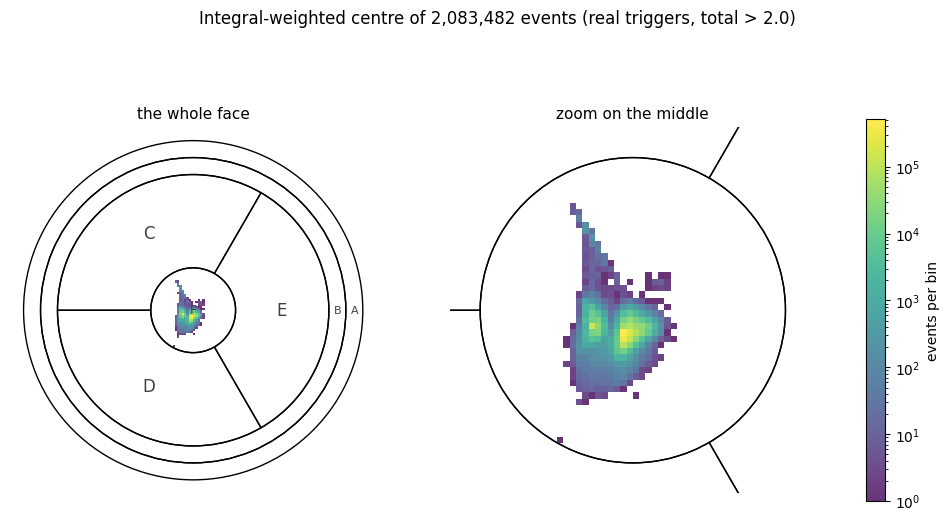

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
for ax, lim in zip(axes, (1.08, 0.3)):
    draw_detector(ax, lim=lim)
    h = ax.hist2d(pos[:, 0], pos[:, 1], bins=int(140 * lim / 1.08) + 20, range=[[-lim, lim], [-lim, lim]], cmap="viridis", norm=colors.LogNorm(), cmin=1, alpha=0.8, zorder=2)
    ax.set_title("the whole face" if lim > 1 else "zoom on the middle", fontsize=11)
fig.colorbar(h[3], ax=axes, shrink=0.8, label="events per bin")
fig.suptitle(f"Integral-weighted centre of {len(pos):,} events (real triggers, total > {THRESH})", fontsize=12)
plt.show()

## The integral of each channel, over the face

Six maps, one per channel. At each place of the face, the mean *share* of the signal that the channel carries (its positive integral over `total`) of the events there, with the detector drawn under the map. A channel that sees an event only when the event is near it shows as a bright spot at its own region; a channel whose share is the same everywhere would be a flat map. Places with fewer than 20 events are left blank. The panels are zoomed on the middle of the face (0.3 of the radius), where the events are; the circle is the centre disc `F`, the lines are the edges of the sectors.

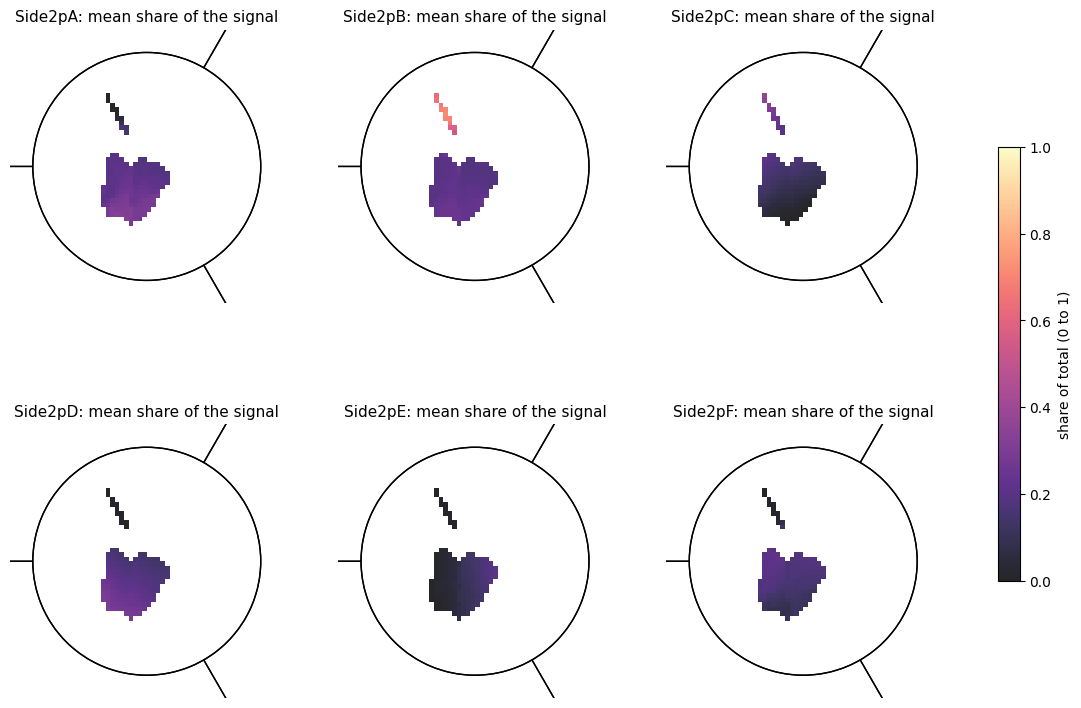

In [7]:
LIM = 0.3
edges = np.linspace(-LIM, LIM, 61)
count, _, _ = np.histogram2d(pos[:, 0], pos[:, 1], bins=[edges, edges])

fig, axes = plt.subplots(2, 3, figsize=(15, 9.4))
for ax, i, k in zip(axes.flat, range(6), LETTERS):
    draw_detector(ax, lim=LIM)
    s, _, _ = np.histogram2d(pos[:, 0], pos[:, 1], bins=[edges, edges], weights=frac[:, i])
    mean = np.where(count >= 20, s / np.maximum(count, 1), np.nan)
    m = ax.pcolormesh(edges, edges, mean.T, cmap="magma", vmin=0, vmax=1, alpha=0.85, zorder=2)
    ax.set_title(f"Side2p{k}: mean share of the signal", fontsize=11)
fig.colorbar(m, ax=axes, shrink=0.6, label="share of total (0 to 1)")
plt.show()

## The detector coloured by the integral itself

The other way round: sort the events by which channel has the largest integral (the "dominant" channel), and for each group colour every region of the detector by the **median offset-subtracted integral** of its own channel. The dominant region is the signal where the event is; the other regions show what leaks into them. Each panel has its own colour scale, from zero to the largest median in that panel.

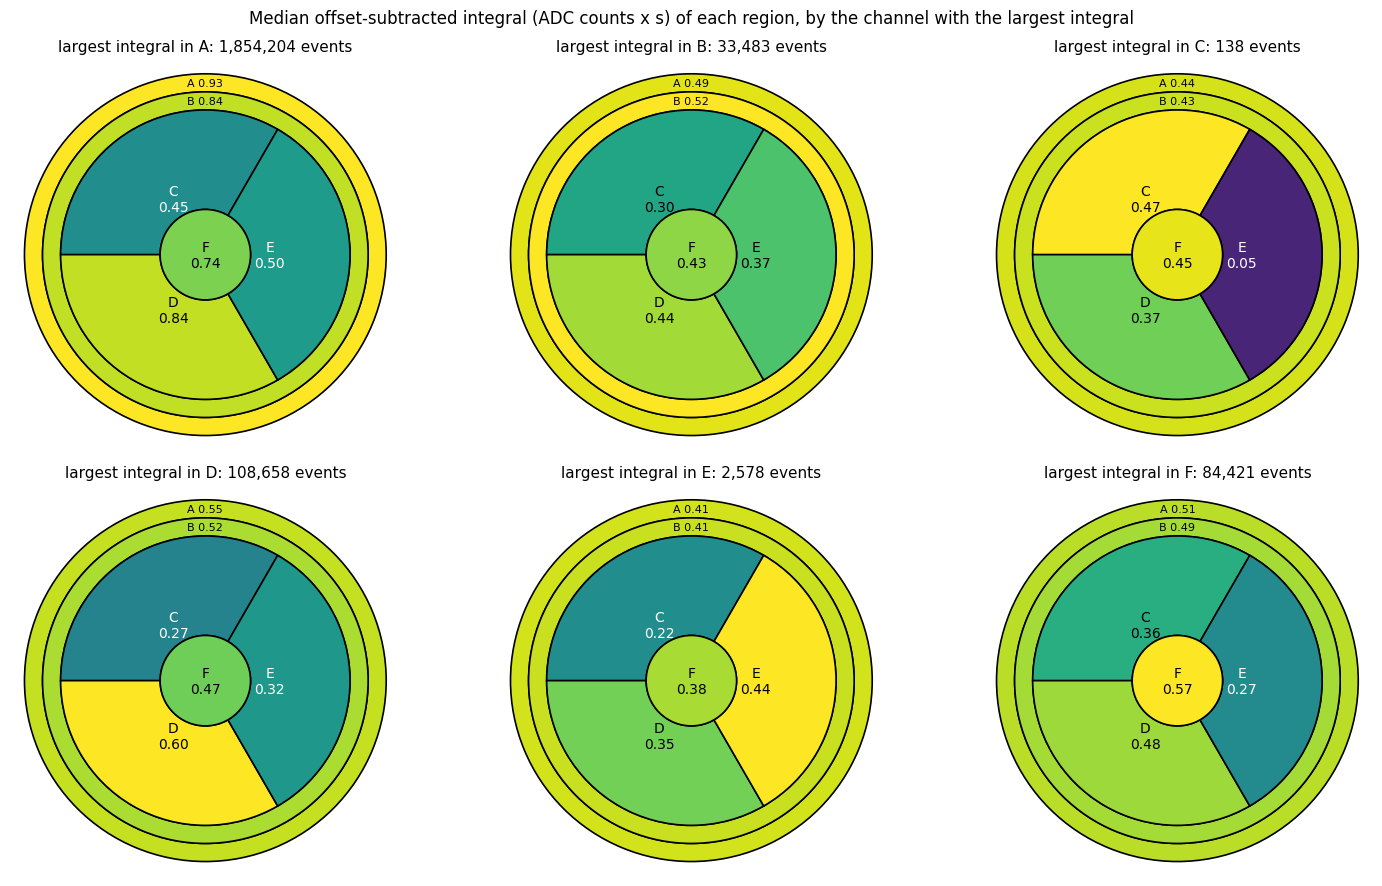

In [8]:
dominant = np.argmax(S[use], axis=1)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, j, kd in zip(axes.flat, range(6), LETTERS):
    sel = dominant == j
    med = np.median(S[use][sel], axis=0) if sel.any() else np.zeros(6)
    norm = colors.Normalize(vmin=0, vmax=max(med.max(), 1e-9))
    fill = {k: cm.viridis(norm(max(med[i], 0))) for i, k in enumerate(LETTERS)}
    draw_detector(ax, fill=fill, label=False, lw=1.2)
    for i, k in enumerate(LETTERS):
        x, y = {"A": (0.0, 0.95), "B": (0.0, 0.85), "F": (0.0, 0.0)}.get(k, tuple(CENTROIDS[i] * 0.75))
        c = "white" if norm(max(med[i], 0)) < 0.55 else "black"
        text = f"{k} {med[i]:.2f}" if k in "AB" else f"{k}" + chr(10) + f"{med[i]:.2f}"
        ax.text(x, y, text, ha="center", va="center", fontsize=8 if k in "AB" else 10, color=c, zorder=6)
    ax.set_title(f"largest integral in {kd}: {sel.sum():,} events", fontsize=11)
fig.suptitle("Median offset-subtracted integral (ADC counts x s) of each region, by the channel with the largest integral", fontsize=12)
fig.tight_layout()
plt.show()

**What this shows, and what is next.** The integrals of the six channels, placed on the face by their own share of the signal, with the detector under the plots. This is the first look at the relative calibration, not the calibration: the integral is in ADC counts times seconds, the position is circular, the ring channels and the centre disc cannot be told apart by position, and the readout of the 12 series is assumed to be the one of `07221203_2025`.

Next: compare the series with each other (is the share of a channel the same in every series?), choose a population of events whose position is known from something other than the channels, and fit the ratios of the channels.